In [14]:
import subprocess
def sh(c):
    r = subprocess.run(c, shell=True, capture_output=True, text=True); print(r.stdout + r.stderr)
sh('git -C /content/code status --short')                # tệp nào bị sửa cục bộ
sh('git -C /content/code stash push -u -m deploy-tay')   # cất đi, không xóa
sh('git -C /content/code pull --ff-only')
sh('git -C /content/code log --oneline -2')              # phải thấy e187a4e ở đầu



No local changes to save

Updating e187a4e..74fe68d
Fast-forward
 tests/test_postprocess.py | 23 +++++++++++++++++------
 1 file changed, 17 insertions(+), 6 deletions(-)
From https://github.com/quocthangtrann/computer_vision_ADAS
   e187a4e..74fe68d  main       -> origin/main

74fe68d Test hậu xử lý: so nhãn với torch theo hòa thay vì ngưỡng tỉ lệ pixel
e187a4e Cell deploy: in lỗi của git pull, tự cất thay đổi cục bộ vào stash rồi pull lại



In [11]:
import os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE, URL = '/content/code', 'github.com/quocthangtrann/computer_vision_ADAS.git'
env = {**os.environ, 'GIT_TERMINAL_PROMPT': '0'}
if not os.path.exists(CODE):
    subprocess.run(f'git clone https://{URL} {CODE}', shell=True, check=True, env=env)
else:
    subprocess.run(f'git -C {CODE} pull', shell=True, check=True, env=env)
subprocess.run(f'rsync -a --exclude .git {CODE}/repo/ /content/drive/MyDrive/capstone_ai/repo/', shell=True, check=True)
try: import segmentation_models_pytorch
except ImportError: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'segmentation-models-pytorch'], check=True)
os.chdir('/content/drive/MyDrive/capstone_ai')
print(subprocess.run(f'git -C {CODE} log --oneline -1', shell=True, capture_output=True, text=True).stdout.strip())
print('mã mới nhất đã ở capstone_ai/repo/ (runtime/, config/, tests/ chạy thẳng từ /content/code) | thư mục làm việc:', os.getcwd())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
e187a4e Cell deploy: in lỗi của git pull, tự cất thay đổi cục bộ vào stash rồi pull lại
mã mới nhất đã ở capstone_ai/repo/ (runtime/, config/, tests/ chạy thẳng từ /content/code) | thư mục làm việc: /content/drive/MyDrive/capstone_ai


In [15]:
import os, sys, json, subprocess
os.chdir('/content/drive/MyDrive/capstone_ai')
ROOT, CODE = '/content/drive/MyDrive/capstone_ai', '/content/code'
CFG = 'pipeline_b.json'      # B2 (mô hình chính). Đánh giá B dự phòng: 'pipeline_b_fallback.json'
PACK = json.load(open(f'{CODE}/config/{CFG}'))['pack_dir']     # gói lấy từ CHÍNH cấu hình: eval_dataset, cell vẽ và bài kiểm gói cùng một nguồn
print('CẤU HÌNH', CFG, '| GÓI', PACK, flush=True)
N = 0                                           # 0 = cả 408 ảnh test (int8ref khoảng 1 đến 3 s mỗi ảnh trên CPU Colab: chưa đo)
BACKENDS = 'int8ref,onnx'
# So sánh các chế độ (cell 4): hậu xử lý standard | fast | half (lưới 160x320) | quarter (80x160); resize pil_bilinear (mốc) | cv2_linear | cv2_area
MODES, RESIZES, CMP_BACKEND, OVERLAP_N = 'standard,fast,half,quarter', 'pil_bilinear,cv2_linear', 'onnx', 60
for f in [f'{PACK}/int8_meta.json', f'{PACK}/int8_model.npz', f'{PACK}/int8_ref.py', f'{PACK}/int8_sim_summary.json', f'{PACK}/fsnet_m_p1s5_c4_640x320.onnx',
          'data/bdd100k_seg.tar', 'data/v2/pilot_drv_x_640x320.npy', 'data/v2/pilot_drv_y_640x320.npy', 'data/v2/pilot_drv_y_320x160.npy', 'data/v2/hd_test_640x320/test_list.csv']:
    print(f'{f:55s}', 'có' if os.path.exists(f) else 'THIẾU')
try: import onnxruntime
except ImportError: subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'onnxruntime'], check=True)
ENV = {**os.environ, 'PYTHONPATH': CODE, 'CAPSTONE_ROOT': ROOT, 'PERCEPTION_PACK': f'{ROOT}/{PACK}', 'PERCEPTION_TEST_DIR': f'{ROOT}/data/v2/hd_test_640x320'}
def run(args, log):
    print('>>>', ' '.join(args), flush=True)
    pr = subprocess.Popen([sys.executable, '-u'] + args, cwd=CODE, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    with open(f'{ROOT}/runs/{log}.log', 'a') as lg:
        for ln in pr.stdout: lg.write(ln); print(ln, end='', flush=True)
    return pr.wait()
os.makedirs('runs', exist_ok=True)


CẤU HÌNH pipeline_b.json | GÓI handoff_s3b_fsnet_m_p1s5_640x320_s4
handoff_s3b_fsnet_m_p1s5_640x320_s4/int8_meta.json      có
handoff_s3b_fsnet_m_p1s5_640x320_s4/int8_model.npz      có
handoff_s3b_fsnet_m_p1s5_640x320_s4/int8_ref.py         có
handoff_s3b_fsnet_m_p1s5_640x320_s4/int8_sim_summary.json có
handoff_s3b_fsnet_m_p1s5_640x320_s4/fsnet_m_p1s5_c4_640x320.onnx có
data/bdd100k_seg.tar                                    có
data/v2/pilot_drv_x_640x320.npy                         có
data/v2/pilot_drv_y_640x320.npy                         có
data/v2/pilot_drv_y_320x160.npy                         có
data/v2/hd_test_640x320/test_list.csv                   có


In [16]:
# 1) kiểm đơn vị của runtime (tầng 2 trên mặt nạ dựng tay, gói nhị phân, ma trận tọa độ, tiền xử lý so với PIL, bilinear so với torch)
#    và với gói B thật: int8ref trùng golden từng bit, lượng tử ảnh test trùng golden, pipeline chạy trọn hai backend.
rc = run(['-m', 'unittest', 'discover', '-s', 'tests', '-v'], 'runtime_tests')
print('KẾT QUẢ kiểm đơn vị:', 'ĐẠT' if rc == 0 else f'KHÔNG ĐẠT (mã {rc}): dán đoạn trên cho tôi')


>>> -m unittest discover -s tests -v
test_iou_drop_sign_and_road (test_eval_helpers.EvalHelpersTest.test_iou_drop_sign_and_road) ... ok
test_lane_strict_counts_missing_center_as_error (test_eval_helpers.EvalHelpersTest.test_lane_strict_counts_missing_center_as_error) ... ok
test_mode_verdict_threshold_and_minimum (test_eval_helpers.EvalHelpersTest.test_mode_verdict_threshold_and_minimum) ... ok
test_resize_verdict_threshold (test_eval_helpers.EvalHelpersTest.test_resize_verdict_threshold) ... ok
test_b_input_grid (test_mapping.MappingTest.test_b_input_grid) ... ok
test_b_logit_grid (test_mapping.MappingTest.test_b_logit_grid) ... ok
test_inverse_roundtrip (test_mapping.MappingTest.test_inverse_roundtrip) ... ok
test_offset_crop (test_mapping.MappingTest.test_offset_crop) ... ok
test_int8ref_matches_golden (test_pack_backend.PackBackendTest.test_int8ref_matches_golden) ... ok
test_pipeline_both_backends (test_pack_backend.PackBackendTest.test_pipeline_both_backends) ... 
  int8ref: pre 

In [17]:
# 2) runtime trên 408 ảnh test: ảnh gốc 1280x720 trong tar -> runtime.pipeline -> mặt nạ, IoU ở lưới 320x160.
#    Phải khớp int8_sim trong +-0,001 (int8ref với "pct", onnx với "fp32" trong int8_sim_summary.json của gói); in thời gian từng khâu.
#    Thời gian ở đây là CPU Colab, KHÔNG phải A53 của board. Cell này chỉ kiểm tính đúng (chế độ standard, resize mặc định); so sánh chế độ ở cell sau.
args = ['-m', 'runtime.eval_dataset', '--root', ROOT, '--config', f'{CODE}/config/{CFG}', '--backends', BACKENDS, '--tol', '0.001',
        '--modes', 'standard', '--resizes', '', '--overlap_n', '0']
if N: args += ['--n', str(N)]
rc = run(args, 'runtime_eval')
if rc != 0: print(f'KHÔNG ĐẠT (mã {rc}): dán đoạn trên cho tôi')


>>> -m runtime.eval_dataset --root /content/drive/MyDrive/capstone_ai --config /content/code/config/pipeline_b.json --backends int8ref,onnx --tol 0.001 --modes standard --resizes  --overlap_n 0
gói /content/drive/MyDrive/capstone_ai/handoff_s3b_fsnet_m_p1s5_640x320_s4 | lưới vào 640x320 | backend ['int8ref', 'onnx'] | hậu xử lý standard | thang vào 0.0207874
đọc ảnh gốc từ /content/drive/MyDrive/capstone_ai/data/bdd100k_seg.tar
408 ảnh test trong manifest, đánh giá 408
  50/408 ảnh | 45s
  100/408 ảnh | 84s
  150/408 ảnh | 120s
  200/408 ảnh | 156s
  250/408 ảnh | 194s
  300/408 ảnh | 230s
  350/408 ảnh | 266s
  400/408 ảnh | 304s
  408/408 ảnh | 309s

=== 1) ảnh sau tiền xử lý so với cache pilot_drv_x_640x320.npy: 0 / 83558400 pixel lệch
    (tham khảo) giải mã JPEG bằng cv2 khác PIL ở [0, 0, 0, 0, 0, 0, 0, 0, 0, 0] pixel trên 10 ảnh đầu: board nhận khung thô từ camera nên không ảnh hưởng
=== 2) IoU ở lưới 320x160 so với int8_sim_summary.json (thứ tự lớp: không đường, không thuộc ta, 

In [18]:
# 3) So sánh các chế độ để giảm pre + post + tier2 (mục tiêu <= 10 ms trên CPU Colab), trên backend onnx (nhanh), cả 408 ảnh.
#    Mục in 5: chế độ hậu xử lý (standard, fast, half, quarter): IoU, lệch tâm làn so với nhãn, thời gian. Tiêu chí đặt trước: tỉ lệ ảnh lệch tâm > 100 px
#              (tính cả ảnh thiếu tâm) xấu hơn standard quá 0,01 thì KHÔNG DÙNG.
#    Mục in 6: resize của tiền xử lý (PIL NumPy mốc, cv2_linear): pixel lệch so với cache, IoU, thời gian. Tiêu chí đặt trước: IoU giảm quá 0,001 thì GIỮ mốc.
#    Mục in 7: chạy gối đầu hai luồng so với tuần tự. Mục in 8: pre + post + tier2 so với mục tiêu.
#    Kết quả ghi ở eval_runtime_cmp/runtime_eval_summary.json (không đè kết quả cell 3). Đo trên onnx FP32, KHÔNG qua lượng tử INT8:
#    muốn thử resize khác trên đường INT8 thì đặt CMP_BACKEND = 'int8ref' (rất chậm).
args = ['-m', 'runtime.eval_dataset', '--root', ROOT, '--config', f'{CODE}/config/{CFG}', '--backends', CMP_BACKEND, '--cmp_backend', CMP_BACKEND, '--out', 'eval_runtime_cmp',
        '--modes', MODES, '--resizes', RESIZES, '--overlap_n', str(OVERLAP_N), '--max_iou_drop', '0.001', '--max_gt100_worse', '0.01', '--target_ms', '10']
if N: args += ['--n', str(N)]
rc = run(args, 'runtime_eval_cmp')
if rc != 0: print(f'mã thoát {rc}: dán đoạn trên cho tôi')


>>> -m runtime.eval_dataset --root /content/drive/MyDrive/capstone_ai --config /content/code/config/pipeline_b.json --backends onnx --cmp_backend onnx --out eval_runtime_cmp --modes standard,fast,half,quarter --resizes pil_bilinear,cv2_linear --overlap_n 60 --max_iou_drop 0.001 --max_gt100_worse 0.01 --target_ms 10
gói /content/drive/MyDrive/capstone_ai/handoff_s3b_fsnet_m_p1s5_640x320_s4 | lưới vào 640x320 | backend ['onnx'] | hậu xử lý standard | thang vào 0.0207874
đọc ảnh gốc từ /content/drive/MyDrive/capstone_ai/data/bdd100k_seg.tar
408 ảnh test trong manifest, đánh giá 408
  50/408 ảnh | 12s
  100/408 ảnh | 23s
  150/408 ảnh | 35s
  200/408 ảnh | 47s
  250/408 ảnh | 59s
  300/408 ảnh | 69s
  350/408 ảnh | 81s
  400/408 ảnh | 93s
  408/408 ảnh | 94s

=== 1) ảnh sau tiền xử lý so với cache pilot_drv_x_640x320.npy: 0 / 83558400 pixel lệch
    (tham khảo) giải mã JPEG bằng cv2 khác PIL ở [0, 0, 0, 0, 0, 0, 0, 0, 0, 0] pixel trên 10 ảnh đầu: board nhận khung thô từ camera nên không ản

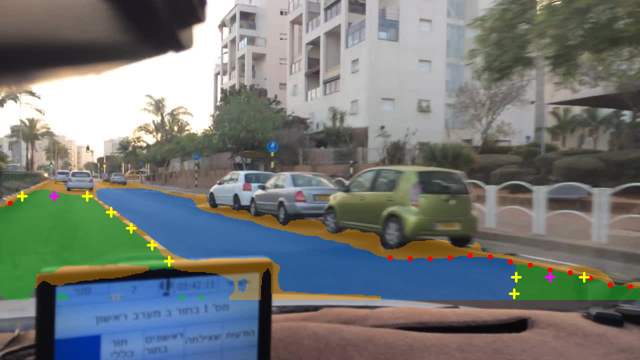

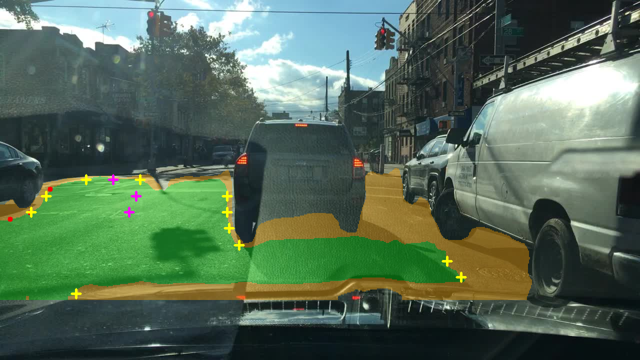

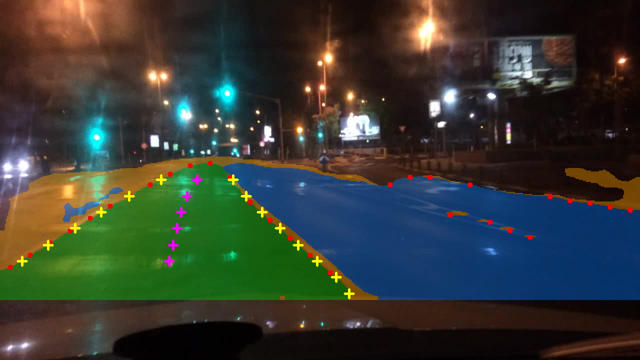

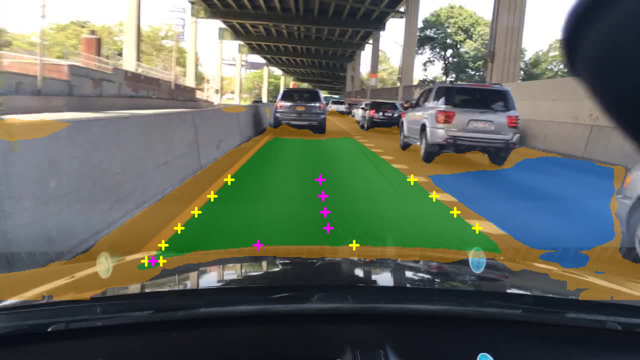

In [19]:
# 4) (tùy chọn) vẽ kết quả lên 4 ảnh test để kiểm bằng mắt: màu lớp, chấm đỏ = ranh giới khoảng trống, chữ thập = mép và tâm làn
import io, csv, numpy as np
sys.path.insert(0, CODE); sys.path.insert(0, f'{ROOT}/repo')
from PIL import Image
from IPython.display import display
from runtime.pipeline import Pipeline
from runtime.viz import overlay
import make_hd_pilot as mhp
pl = Pipeline(f'{CODE}/config/{CFG}', ROOT, backend='onnx')
man = list(csv.DictReader(open('data/v2/pilot_drv_manifest.csv'))); te = [r for r in man if r['split_v2'] == 'test']
tar = '/content/hd_scratch/bdd100k_seg.tar' if os.path.exists('/content/hd_scratch/bdd100k_seg.tar') else 'data/bdd100k_seg.tar'
imgs, _ = mhp.index_tar(tar); fh = open(tar, 'rb'); os.makedirs('eval_runtime', exist_ok=True)
for k in [0, 100, 200, 300]:
    off, size = imgs[(te[k]['v1_split'], te[k]['id'])]; fh.seek(off)
    frame = np.asarray(Image.open(io.BytesIO(fh.read(size))).convert('RGB'))
    r = pl.process(frame, keep=True)
    im = Image.fromarray(overlay(frame, r)); im.save(f'eval_runtime/vis_test_{k:03d}.png'); display(im.resize((640, 360)))
